# Исследовательский анализ данных TAWOS

Ноутбук содержит первичный аудит таблицы `Issue`, проверку временных полей, анализ истории изменений и отдельный анализ текущей обучающей выборки.

## 1. Настройка окружения

In [70]:
import pandas as pd
from sqlalchemy import text
import matplotlib.pyplot as plt

from data_access.connection import engine
from data_access.config import project_path


pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

## 2. Загрузка исходных данных

Получение общего среза таблицы `Issue` для первичного исследования.

In [71]:
query = text("""
    SELECT
        i.ID,
        i.Issue_Key,
        i.Project_ID,
        p.Project_Key,
        i.Title,
        i.Description,
        i.Type,
        i.Priority,
        i.Status,
        i.Creation_Date,
        i.In_Progress_Minutes,
        i.Resolution_Date,
        i.Resolution_Time_Minutes
    FROM Issue AS i
    LEFT JOIN Project AS p
        ON p.ID = i.Project_ID
    ORDER BY i.ID
""")

df = pd.read_sql_query(query, engine)

## 3. Общая структура данных

Размер выборки, типы данных, число уникальных значений и первые строки.

In [72]:
resolved_df = df[
    df["Creation_Date"].notna() 
    &
    df["Resolution_Date"].notna()
]

print("Всего задач:", len(df))
print("Всего закрытых задач:", len(resolved_df))
print("Всего незакрытых задач:", df["Resolution_Date"].isna().sum())

Всего задач: 458232
Всего закрытых задач: 352632
Всего незакрытых задач: 105600


In [73]:
df.shape

(458232, 13)

In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 458232 entries, 0 to 458231
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   ID                       458232 non-null  int64         
 1   Issue_Key                458232 non-null  str           
 2   Project_ID               458232 non-null  int64         
 3   Project_Key              458232 non-null  str           
 4   Title                    458232 non-null  str           
 5   Description              458232 non-null  str           
 6   Type                     458232 non-null  str           
 7   Priority                 458232 non-null  str           
 8   Status                   458232 non-null  str           
 9   Creation_Date            458232 non-null  datetime64[us]
 10  In_Progress_Minutes      458232 non-null  float64       
 11  Resolution_Date          352632 non-null  datetime64[us]
 12  Resolution_Time_Minutes  45

In [75]:
df.nunique().sort_values()

Priority                       18
Type                           24
Project_Key                    39
Project_ID                     39
Status                         76
In_Progress_Minutes         26416
Resolution_Time_Minutes    197864
Resolution_Date            304906
Title                      412868
Description                421334
Creation_Date              424980
ID                         458232
Issue_Key                  458232
dtype: int64

In [76]:
df.head()

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
0,65,XD-3768,1,XD,"""How do I make a job restartable in spring xd""","""The jobs that appear under Executions section of Jobs in spring xd admin ui, has restart button...",Bug,Major,To Do,2017-07-10 13:41:25,0.0,NaT,0.0
1,66,XD-3767,1,XD,"""admin config timezone command does not work""","""Working with Spring-XD version 1.3.2.RELEASE Starting the server with {{xd-singlenode}} comman...",Bug,Trivial,To Do,2017-06-26 16:26:27,0.0,NaT,0.0
2,67,XD-3766,1,XD,"""Module Upload command not pushing jar to all containers""","""My project 7 node cluster and in that 2 node are Admin containers and remaining are non admin c...",Bug,Major,To Do,2017-05-19 22:28:43,0.0,NaT,0.0
3,68,XD-3765,1,XD,"""Fix stream failover ""","""See https://github.com/spring-projects/spring-xd/issues/1924""",Story,Minor,Done,2017-03-21 16:54:44,0.0,2017-03-21 16:55:23,0.0
4,69,XD-3764,1,XD,"""SpringXD Job is still executing even after forceful Server shutdown""","""I'm trying to run a Job on SpringXD and the job has 7 steps, When I reach step 4 i'm shutting d...",Bug,Major,To Do,2017-03-06 20:01:41,0.0,NaT,0.0


## 4. Завершённые задачи и качество временных полей

Проверка наличия даты завершения, слишком коротких задач, времени в работе и пропущенных значений.

In [77]:
filtered = df.dropna(subset=["Resolution_Date"])

print(f"{len(filtered)} - Задачи с указанным сроком выполнения")
print(f"{len(df) - len(filtered)} - Задачи без указанного срока выполнения")

352632 - Задачи с указанным сроком выполнения
105600 - Задачи без указанного срока выполнения


In [78]:
filtered = df[
    (df["Resolution_Date"].isna())
]

filtered

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
0,65,XD-3768,1,XD,"""How do I make a job restartable in spring xd""","""The jobs that appear under Executions section of Jobs in spring xd admin ui, has restart button...",Bug,Major,To Do,2017-07-10 13:41:25,0.0,NaT,0.0
1,66,XD-3767,1,XD,"""admin config timezone command does not work""","""Working with Spring-XD version 1.3.2.RELEASE Starting the server with {{xd-singlenode}} comman...",Bug,Trivial,To Do,2017-06-26 16:26:27,0.0,NaT,0.0
2,67,XD-3766,1,XD,"""Module Upload command not pushing jar to all containers""","""My project 7 node cluster and in that 2 node are Admin containers and remaining are non admin c...",Bug,Major,To Do,2017-05-19 22:28:43,0.0,NaT,0.0
4,69,XD-3764,1,XD,"""SpringXD Job is still executing even after forceful Server shutdown""","""I'm trying to run a Job on SpringXD and the job has 7 steps, When I reach step 4 i'm shutting d...",Bug,Major,To Do,2017-03-06 20:01:41,0.0,NaT,0.0
5,70,XD-3763,1,XD,"""Duplicate entries in table XD_JOB_REGISTRY""","""Hello, I have encountered following problem while using Spring XD in DIRT (distributed) mode. ...",Bug,Major,To Do,2017-01-23 10:21:08,0.0,NaT,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
457950,508754,SERVER-293,33,SERVER,"""embedded fields don't work with csv export""","""See: http://groups.google.com/group/mongodb-user/browse_thread/thread/d7f1685d006ae4c7""",Bug,Major - P3,Closed,2009-09-13 06:58:28,0.0,NaT,0.0
457976,508780,SERVER-267,33,SERVER,"""Wildcard support in index/query/projection=""","""db.foo.ensureIndex( { """"a.*.b"""" : 1 } ) db.foo.find( { """"a.*.b"""" : 5 } ) db.foo.find( {} , { """"...",Improvement,Major - P3,Open,2009-08-27 00:01:01,0.0,NaT,0.0
458010,508814,SERVER-233,33,SERVER,"""make admin user be able to be authenticated against any db""",,Improvement,Minor - P4,Open,2009-08-12 16:27:51,0.0,NaT,0.0
458087,508891,SERVER-153,33,SERVER,"""javascript sort helper for custom sorting / indexing""",,New Feature,Major - P3,Open,2009-07-13 11:27:33,0.0,NaT,0.0


In [79]:
filtered = df[
    (df["Status"] == "Done") &
    (df["Resolution_Time_Minutes"] < 5.0)
]

print(f"{len(filtered)} - Количество задач, чье время выполнения практически близко к нулю")

1418 - Количество задач, чье время выполнения практически близко к нулю


In [80]:
filtered = df[
    (df["In_Progress_Minutes"] != 0.0)
]

filtered.sample(10)

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
353422,404226,TIMOB-26070,12,TIMOB,"""Create 7.2.0 sample app""","""We need a sample app for our 7.2.0 release that demonstrates some GDPR features that we offer, ...",Story,Medium,Resolved,2018-05-26 09:21:18,106621.0,2018-08-11 01:02:41,110381.0
120076,120145,JRASERVER-3155,18,JRASERVER,"""Pretty URL's seem to go AWOL occasionally...""","""Under some conditions, I still get URLS like http://jira.atlassian.com/secure/ViewIssue.jspa?ke...",Bug,Low,Closed,2004-02-16 21:34:06,2500.0,2004-02-20 04:44:06,4749.0
225899,225968,DM-22328,28,DM,"""Add nublado into argo-cd application to run it on -int""","""Now that we have a working nublado helm chart, we can tie it into argocd's application framewor...",Story,,Done,2019-11-22 19:53:32,110.0,2019-11-22 21:44:08,110.0
260491,260560,EVG-6049,43,EVG,"""Patches to the enterprise module are applied to the wrong base on spawn hosts""","""If you launch a spawn host with the artifacts from the patch test with changes to the enterpris...",Bug,Major - P3,Closed,2019-04-04 19:17:57,3377.0,2019-05-09 14:37:57,50120.0
243978,244047,DM-3931,28,DM,"""sandbox-stackbuild issues""","""A number of issues with sandbox-stackbuild, or rather its infrastructure. 1. Problem with th...",Story,,Done,2015-09-22 16:41:44,326.0,2017-11-27 22:03:23,1148061.0
9849,9918,NEXUS-4863,3,NEXUS,"""Nexus Plugin Manager matches plugin interdependencies by GA only on loaded plugins""","""Nexus Plugin Manager matches plugin interdependencies by GA only on loaded plugins, but it shou...",Bug,Major,Closed,2012-02-14 09:13:27,175.0,2012-03-01 20:07:14,23693.0
260501,260570,EVG-6039,43,EVG,"""Add functionality to recent_tasks endpoint to bucket and filter by project and distro""","""We use the recent tasks endpoint to monitor production, particularly after deploys or if a user...",Task,Major - P3,Closed,2019-04-03 16:21:10,8341.0,2019-05-20 16:24:27,67683.0
109507,109576,JRASERVER-16984,18,JRASERVER,"""Refactor select and multi-select searcher and JQL classes to handle case insensitivity properly.""",,Suggestion,,Closed,2009-04-21 05:40:13,1522.0,2009-04-28 03:19:03,9938.0
361781,412585,TIMOB-13877,12,TIMOB,"""BlackBerry : Unable to scroll the scrollview till the last element or bottom""","""This is a regression. Description: 1. Create an app for BB with the following code: {code}...",Bug,High,Closed,2013-05-15 22:23:25,4042.0,2013-05-23 18:13:51,11270.0
348984,399786,TISTUD-3984,13,TISTUD,"""TiApp: mobileweb module missing version""","""Notice the MobileWeb module version is missing from TiApp Overview, but it correctly and soundl...",Bug,High,Closed,2013-03-28 22:26:25,5431.0,2013-04-01 20:02:57,5556.0


In [81]:
df.isna()

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes
0,False,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
458227,False,False,False,False,False,False,False,False,False,False,False,False,False
458228,False,False,False,False,False,False,False,False,False,False,False,False,False
458229,False,False,False,False,False,False,False,False,False,False,False,False,False
458230,False,False,False,False,False,False,False,False,False,False,False,False,False


## 5. Распределения категориальных признаков

Распределения задач по приоритетам, типам и текущим статусам.

In [82]:
query = text("""
    SELECT
        COALESCE(Priority, 'Не указан') AS Priority,
        COUNT(*) AS Issue_Count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage
    FROM Issue
    GROUP BY Priority
    ORDER BY Issue_Count DESC
""")

priority_stats = pd.read_sql_query(query, engine)

priority_stats

,Priority,Issue_Count,Percentage
0,,124073,27.08
1,Low,65819,14.36
2,Major - P3,57146,12.47
3,Medium,56920,12.42
4,Minor,55819,12.18
5,Major,34212,7.47
6,High,24447,5.34
7,Critical,11341,2.47
8,Trivial,6617,1.44
9,Minor - P4,5947,1.30


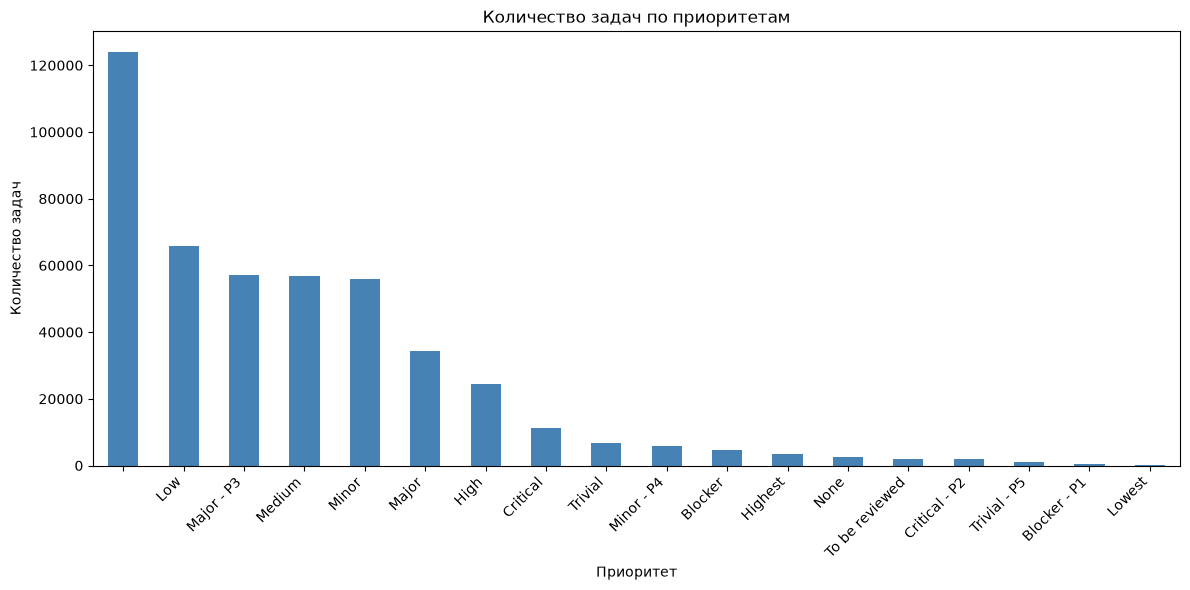

In [83]:
ax = priority_stats.plot.bar(
    x="Priority",
    y="Issue_Count",
    figsize=(12, 6),
    legend=False,
    color="steelblue",
)

ax.set_title("Количество задач по приоритетам")
ax.set_xlabel("Приоритет")
ax.set_ylabel("Количество задач")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [84]:
query = text("""
    SELECT
        i.Type AS Type,
        COUNT(*) AS Issue_Count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage
    FROM Issue AS i
    GROUP BY Type
    ORDER BY Issue_Count DESC
""")

type_stats = pd.read_sql_query(query, engine)

type_stats

,Type,Issue_Count,Percentage
0,Bug,215570,47.04
1,Suggestion,96370,21.03
2,Improvement,42691,9.32
3,Story,31394,6.85
4,Task,28338,6.18
5,Sub-task,14396,3.14
6,New Feature,14239,3.11
7,Epic,4157,0.91
8,Enhancement Request,3239,0.71
9,Support Request,2368,0.52


In [85]:
query = text("""
    SELECT
        i.Status AS Status,
        COUNT(*) AS Issue_Count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS Percentage
    FROM Issue AS i
    GROUP BY Status
    ORDER BY Issue_Count DESC
""")

status_stats = pd.read_sql_query(query, engine)

status_stats

,Status,Issue_Count,Percentage
0,Closed,334368,72.97
1,Gathering Interest,27238,5.94
2,Done,26825,5.85
3,Open,24922,5.44
4,Resolved,11548,2.52
5,Gathering Impact,8303,1.81
6,Complete,5151,1.12
7,To Do,4909,1.07
8,Won't Fix,1932,0.42
9,Needs Triage,1488,0.32


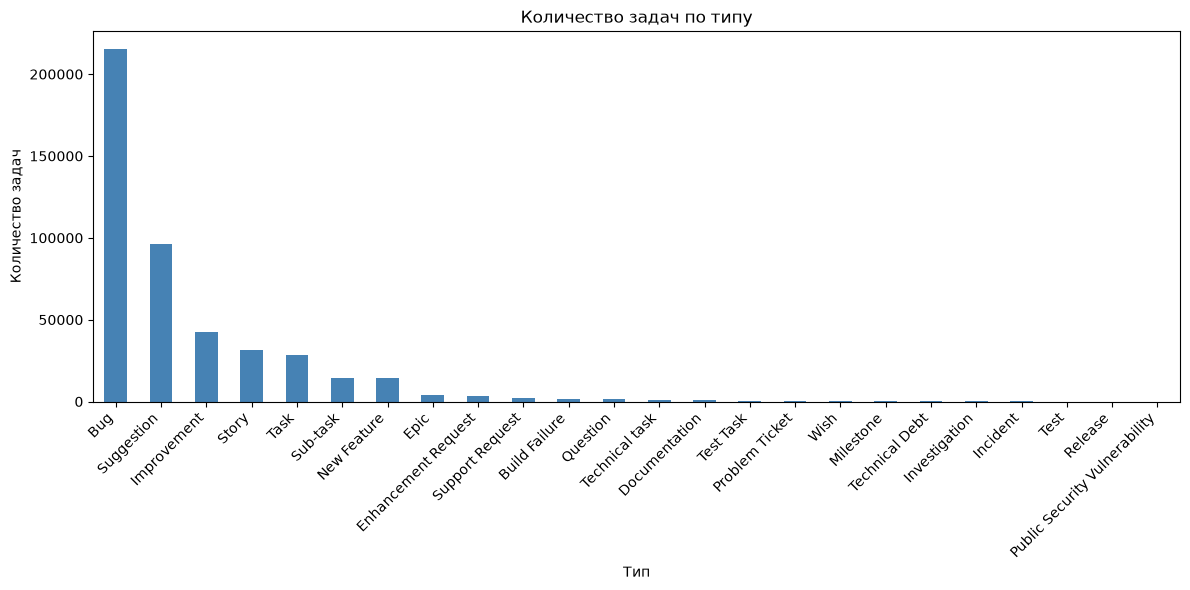

In [86]:
ax = type_stats.plot.bar(
    x="Type",
    y="Issue_Count",
    figsize=(12, 6),
    legend=False,
    color="steelblue"
)

ax.set_title("Количество задач по типу")
ax.set_xlabel("Тип")
ax.set_ylabel("Количество задач")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Сравнение способов расчёта длительности

Сравнение календарной длительности `Resolution_Date - Creation_Date` с полем `Resolution_Time_Minutes`.

In [87]:
resolved_df[
    ["Creation_Date", "Resolution_Date"]
].dtypes

Creation_Date      datetime64[us]
Resolution_Date    datetime64[us]
dtype: object

In [88]:
before = resolved_df["Resolution_Date"].isna().sum()

resolved_df["Creation_Date"] = pd.to_datetime(
    resolved_df["Creation_Date"],
    errors="coerce",
)

resolved_df["Resolution_Date"] = pd.to_datetime(
    resolved_df["Resolution_Date"],
    errors="coerce",
)

after = resolved_df["Resolution_Date"].isna().sum()

print("Количество некорректных дат:", after - before)

resolved_df["Duration_Days"] = (
    resolved_df["Resolution_Date"]
    - resolved_df["Creation_Date"]
).dt.total_seconds() / 86_400

Количество некорректных дат: 0


In [89]:
resolved_df["Resolution_Time_Days"] = resolved_df["Resolution_Time_Minutes"] / 1440

resolved_df["Duration_Difference"] = resolved_df["Duration_Days"] - resolved_df["Resolution_Time_Days"]

In [90]:
resolved_df

,ID,Issue_Key,Project_ID,Project_Key,Title,Description,Type,Priority,Status,Creation_Date,In_Progress_Minutes,Resolution_Date,Resolution_Time_Minutes,Duration_Days,Resolution_Time_Days,Duration_Difference
3,68,XD-3765,1,XD,"""Fix stream failover ""","""See https://github.com/spring-projects/spring-xd/issues/1924""",Story,Minor,Done,2017-03-21 16:54:44,0.0,2017-03-21 16:55:23,0.0,0.000451,0.000000,0.000451
20,85,XD-3748,1,XD,"""Unable to register the JMX bean MessageHistory from Spring Integration""","""If I try to use <int:message-history/> when developing a Spring XD module, it fails when try to...",Bug,Minor,Done,2016-02-24 10:51:02,87.0,2016-12-23 14:49:45,436558.0,303.165775,303.165278,0.000498
21,86,XD-3747,1,XD,"""Rabbit Bus: Expose ChannelCacheSize on CachingConnectionFactory""","""http://stackoverflow.com/questions/35563064/processing-messages-through-namedchannels-with-pref...",Improvement,Minor,Done,2016-02-23 18:31:38,2.0,2016-12-23 14:49:26,437537.0,303.845694,303.845139,0.000556
22,87,XD-3746,1,XD,"""Update Spring Framework to 4.2.4""",,Improvement,Minor,Done,2016-02-23 18:18:48,0.0,2016-02-23 18:19:07,0.0,0.000220,0.000000,0.000220
23,88,XD-3745,1,XD,"""Update Spring-AMQP to 3.6, RabbitMQ Client to 1.5.4""","""Update to amqp-client 3.6.0 and spring-amqp 1.5.4""",Improvement,Minor,Done,2016-02-23 18:04:09,0.0,2016-02-23 18:04:42,0.0,0.000382,0.000000,0.000382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458227,509031,SERVER-5,33,SERVER,"""file configuration""",""" make mongod use boost argument handling so can read frmo file""",Improvement,Minor - P4,Closed,2009-04-09 09:15:20,0.0,2009-07-14 16:27:28,138672.0,96.300093,96.300000,0.000093
458228,509032,SERVER-4,33,SERVER,"""assure stack size per thread isn't too big""","""we might have hundreds or thousands of clients connected -- in which case it would waste a lot ...",Improvement,Minor - P4,Closed,2009-04-09 09:14:27,0.0,2010-02-25 21:42:33,464428.0,322.519514,322.519444,0.000069
458229,509033,SERVER-3,33,SERVER,"""implement inf. loop protection in spider monkey""","""need to make inf. loop protection configurable. may hold off on this until decide on javascript...",Improvement,Minor - P4,Closed,2009-04-09 09:02:06,0.0,2009-05-27 14:08:21,69426.0,48.212674,48.212500,0.000174
458230,509034,SERVER-2,33,SERVER,"""inf. loop protection for $where and dbEval""",,Improvement,Major - P3,Closed,2009-04-09 08:59:26,0.0,2009-08-25 11:29:57,198870.0,138.104525,138.104167,0.000359


In [91]:
import numpy as np


matches = np.isclose(
    resolved_df["Duration_Days"],
    resolved_df["Resolution_Time_Days"],
    atol=1 / 1440,
    rtol=0,
)

pd.Series(matches).value_counts()

True     277288
False     75344
Name: count, dtype: int64

## 7. История изменений задач (`Change_Log`)

Анализ изменений статусов, типов изменений и приоритетов.

### 7.1. Изменения статусов

In [92]:
query = text("""
    SELECT
        i.ID,
        i.Issue_Key,
    	COUNT(i.Issue_Key) AS status_change_counts
    FROM Issue AS i
    LEFT JOIN Change_Log AS cl
    	ON cl.Issue_ID = i.ID
    WHERE LOWER(cl.Change_Type) = 'status' AND i.Resolution_Date IS NOT NULL
    GROUP BY i.Issue_Key, i.ID
    ORDER BY i.ID
""")

change_log_status_df = pd.read_sql_query(query, engine)

print("Количество задач, где изменялся статус:", len(change_log_status_df))

change_log_status_df

Количество задач, где изменялся статус: 352632


,ID,Issue_Key,status_change_counts
0,68,XD-3765,2
1,85,XD-3748,9
2,86,XD-3747,9
3,87,XD-3746,4
4,88,XD-3745,4
...,...,...,...
352627,509031,SERVER-5,3
352628,509032,SERVER-4,3
352629,509033,SERVER-3,3
352630,509034,SERVER-2,2


### 7.2. Типы изменений

In [93]:
query = text("""
    SELECT Change_Type, COUNT(Change_Type) AS Count_Changes FROM Change_Log
    GROUP BY Change_Type
""")

change_type_count_df = pd.read_sql_query(query, engine)

change_type_count_df

,Change_Type,Count_Changes
0,OTHER,6726893
1,STATUS,1779677
2,DESCRIPTION,348103
3,PEOPLE,349551
4,STORY_POINT,49195


### 7.3. Изменения приоритетов

In [94]:
query1 = text("""
    SELECT
        COUNT(*) AS Priority_Changes,
        COUNT(DISTINCT Issue_ID) AS Issues_With_Priority_Changes
    FROM Change_Log
    WHERE LOWER(Field) = 'priority';
""")

query2 = text("""
    SELECT
    	COUNT(*) AS Priority_Changes,
    	COUNT(DISTINCT cl.Issue_ID) AS Issues_With_Priority_Changes
    FROM Issue AS i
    JOIN Change_Log AS cl
    	ON i.ID = cl.Issue_ID
    WHERE LOWER(cl.Field) = 'priority' AND i.Resolution_Date IS NOT NULL
""")

priority_changes = pd.read_sql_query(query2, engine)

priority_changes

,Priority_Changes,Issues_With_Priority_Changes
0,96227,83986


In [95]:
query = text("""
    SELECT
        i.Issue_Key,
        cl.Creation_Date,
        cl.From_String AS Previous_Priority,
        cl.To_String AS New_Priority
    FROM Change_Log AS cl
    JOIN Issue AS i
        ON i.ID = cl.Issue_ID
    WHERE LOWER(cl.Field) = 'priority'
    ORDER BY cl.Creation_Date
    LIMIT 100;
""")

priority_changes_df = pd.read_sql_query(query, engine)

priority_changes_df.sample(10)

,Issue_Key,Creation_Date,Previous_Priority,New_Priority
52,JRASERVER-3571,2004-04-19 01:13:54,Blocker,Major
23,JRASERVER-27,2002-02-11 09:57:00,,Minor
39,CONFSERVER-746,2004-02-20 02:48:32,Critical,Minor
25,JRASERVER-29,2002-02-11 12:09:00,,Major
61,JRASERVER-3738,2004-05-12 06:10:03,Major,Critical
26,JRASERVER-30,2002-02-11 12:42:00,,Major
41,CONFSERVER-870,2004-03-02 22:54:17,Blocker,Major
70,CONFSERVER-1257,2004-05-26 03:46:22,Major,Critical
20,JRASERVER-24,2002-02-11 07:35:00,,Minor
62,JRASERVER-3754,2004-05-14 12:12:33,Major,Minor


## 8. Анализ обучающей выборки

Данные загружаются тем же SQL-запросом, который используется для составления обучающего датасета.

### 8.1. Распределение длительности задач

Ось длительности логарифмическая, поскольку распределение имеет длинный правый хвост.

In [96]:
query_path = project_path.query("training_dataset.sql")
training_query = text(query_path.read_text(encoding="utf-8"))

training_df = pd.read_sql_query(training_query, engine)
duration = training_df["Duration_Days"].dropna()

duration.describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

count    251872.000000
mean         50.663282
std          79.344728
min           0.003500
50%          13.905600
75%          59.613200
90%         170.002690
95%         248.936480
99%         338.105492
max         364.999800
Name: Duration_Days, dtype: float64

In [97]:
training_df

,ID,Project_ID,Creation_Date,Description_Issue_Length,Resolution_Date,Duration_Days,Status,Initial_Priority,Initial_Type,Description_Project_Length,Comment_Count,Comment_Total_Length,Change_Count
0,85,1,2016-02-24 10:51:02,249,2016-12-23 14:49:45,303.1658,Done,Minor,Bug,146,1,791.0,13
1,86,1,2016-02-23 18:31:38,125,2016-12-23 14:49:26,303.8457,Done,Minor,Improvement,146,0,0.0,13
2,89,1,2016-02-22 15:27:31,384,2016-02-22 18:41:31,0.1347,Done,Minor,Story,146,0,0.0,11
3,90,1,2016-02-17 14:28:31,18,2016-02-21 02:28:25,3.4999,Done,Minor,Bug,146,0,0.0,10
4,91,1,2016-02-16 14:59:06,579,2016-02-19 20:04:19,3.2120,Done,Minor,Improvement,146,0,0.0,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...
251867,509031,33,2009-04-09 09:15:20,68,2009-07-14 16:27:28,96.3001,Closed,Major,Improvement,130,0,0.0,11
251868,509032,33,2009-04-09 09:14:27,192,2010-02-25 21:42:33,322.5195,Closed,Major,Improvement,130,3,216.0,19
251869,509033,33,2009-04-09 09:02:06,107,2009-05-27 14:08:21,48.2127,Closed,Minor - P4,Bug,130,6,1178.0,17
251870,509034,33,2009-04-09 08:59:26,0,2009-08-25 11:29:57,138.1045,Closed,Major - P3,Improvement,130,1,73.0,14


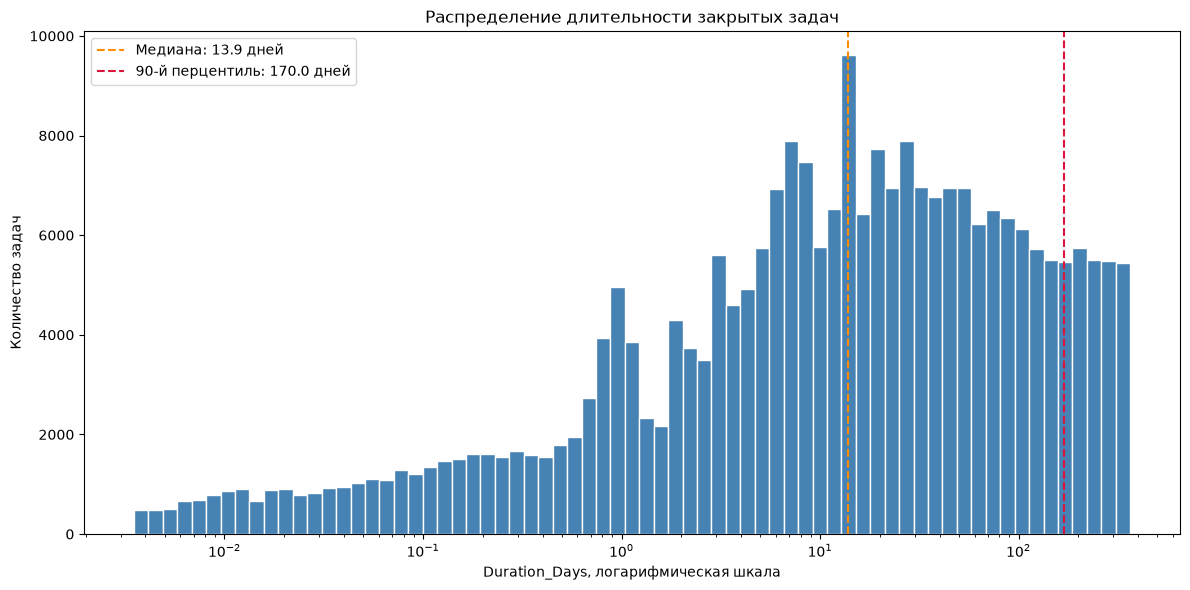

In [98]:
duration_bins = np.geomspace(
    duration.min(),
    duration.max(),
    70,
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    duration,
    bins=duration_bins,
    color="steelblue",
    edgecolor="white",
)
ax.set_xscale("log")

median_duration = duration.median()
percentile_90 = duration.quantile(0.90)

ax.axvline(
    median_duration,
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {median_duration:.1f} дней",
)
ax.axvline(
    percentile_90,
    color="crimson",
    linestyle="--",
    label=f"90-й перцентиль: {percentile_90:.1f} дней",
)

ax.set_title("Распределение длительности закрытых задач")
ax.set_xlabel("Duration_Days, логарифмическая шкала")
ax.set_ylabel("Количество задач")
ax.legend()

plt.tight_layout()
plt.show()

### 8.2. Статистика по годам

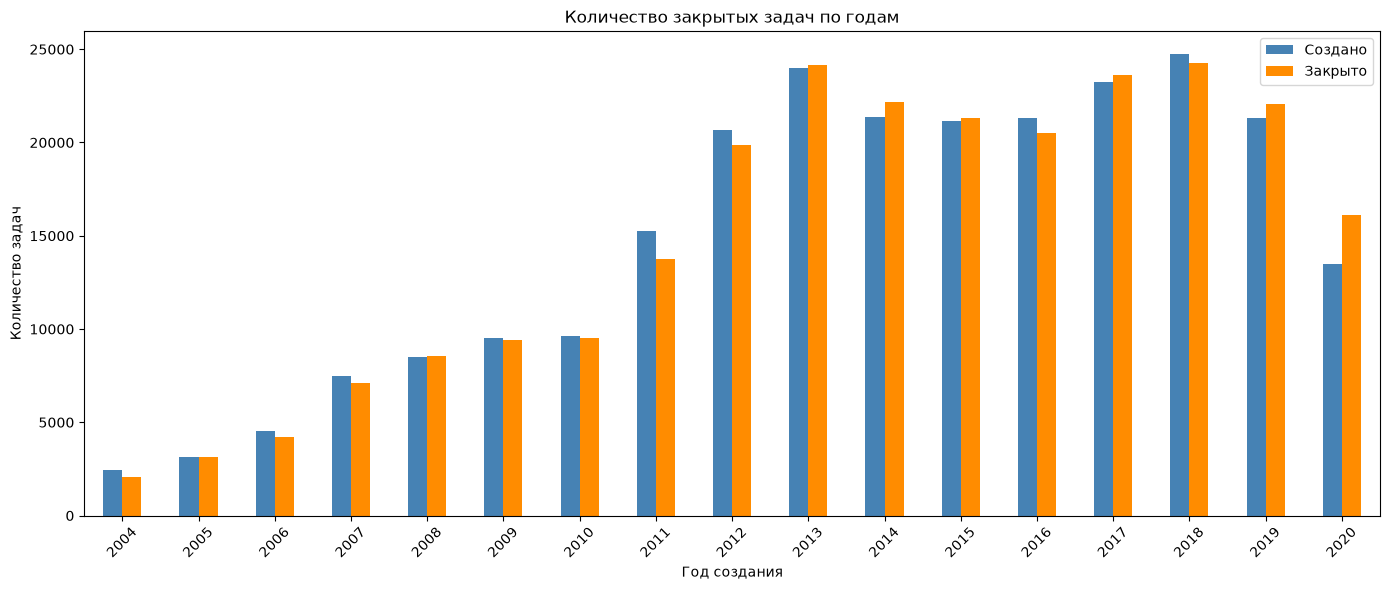

In [99]:
creation_year = training_df["Creation_Date"].dt.year
resolution_year = training_df["Resolution_Date"].dt.year

tasks_by_year = pd.DataFrame({
    "Создано": creation_year.value_counts().sort_index(),
    "Закрыто": resolution_year.value_counts().sort_index(),
}).fillna(0).sort_index()


ax = tasks_by_year.plot.bar(
    figsize=(14, 6),
    color=["steelblue", "darkorange"],
)

ax.set_title("Количество закрытых задач по годам")
ax.set_xlabel("Год создания")
ax.set_ylabel("Количество задач")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [100]:
yearly_duration_stats = (
    training_df.groupby(creation_year)["Duration_Days"]
    .agg(
        count="size",
        mean="mean",
        median="median",
        q90=lambda values: values.quantile(0.90),
    )
)

yearly_duration_stats

,count,mean,median,q90
Creation_Date,,,,
2004,2468,54.780610,14.44185,167.72345
2005,3153,49.719514,6.63250,208.65700
2006,4540,54.303925,9.37450,188.99913
2007,7497,54.039564,9.66920,193.73046
2008,8512,47.930520,9.10050,167.89717
2009,9507,45.141372,9.26080,161.79840
2010,9615,51.258311,14.57800,164.95798
2011,15257,60.260055,15.05430,211.56192
2012,20687,62.197641,15.19900,224.97992


## 9. Эксперимент: статусы задач из обучающей выборки

Здесь будет анализ переходов статусов только для задач, попавших в обучающую выборку, и подготовка правил их унификации.

In [101]:
query_path = project_path.query("training_dataset.sql")
query = text(query_path.read_text(encoding="utf-8"))

issue_df = pd.read_sql_query(query, engine)
issue_df = issue_df[issue_df["Creation_Date"] >= '2010-01-01']
print("Количество строк: ", len(issue_df))

issue_df["Status"].value_counts(dropna=False)


status_query = text("""
    SELECT
        i.ID AS Issue_ID,
        i.Project_ID,
        cl.Creation_Date AS Status_Changed_At,
        cl.From_String AS Previous_Status,
        cl.To_String AS New_Status
    FROM Issue AS i
    JOIN Change_Log AS cl
        ON cl.Issue_ID = i.ID
    WHERE LOWER(cl.Field) = 'status'
        AND i.Resolution_Date > DATE_ADD(
            i.Creation_Date,
            INTERVAL 5 MINUTE
        )
        AND i.Resolution_Date <= DATE_ADD(
            i.Creation_Date,
            INTERVAL 365 DAY
        )
        AND i.Creation_Date >= '2004-01-01'
    ORDER BY
        i.Project_ID,
        i.ID,
        cl.Creation_Date,
        cl.ID
""")

status_history_df = pd.read_sql_query(status_query, engine)

status_history_df["New_Status"].value_counts(dropna=False)

Количество строк:  216195


New_Status
Closed                             258789
Resolved                           158893
In Progress                        103967
Open                                54697
Done                                34609
In Code Review                      28996
Waiting for integration review      26978
In Review                           19480
Development in progress             18101
Waiting for peer review             17592
Integration review in progress      17517
Waiting for testing                 17469
Testing in progress                 17463
Reopened                            16698
Tested                              15352
Peer review in progress             14551
Needs Scheduling                    11827
Reviewed                             8703
Quality Review                       7875
Awaiting Quality Review              5295
To Do                                4827
Technical Review                     4527
Verified                             4520
In CR Review           

In [ ]:
project_status_stats = (
    status_history_df
    .groupby(["Project_ID", "New_Status"])
    .agg(
        Transition_Count=("Issue_ID", "size"),
        Issue_Count=("Issue_ID", "nunique"),
    )
    .reset_index()
    .sort_values(
        ["Project_ID", "Issue_Count"],
        ascending=[True, False],
    ) 
)

project_status_stats

,Project_ID,New_Status,Transition_Count,Issue_Count
0,1,Done,3037,2918
2,1,In Progress,2222,2038
1,1,In PR,660,618
3,1,To Do,204,191
4,2,Closed,608,601
...,...,...,...,...
581,44,Accepted,2,2
601,44,Reopened,2,2
603,44,Reviewing,3,2
596,44,Not Being Considered,1,1
